
# Credit Card Fraud Detection — Supervised Learning Pipeline
**Dataset:** Credit Card Fraud Detection (ULB Machine Learning Group), 284,807 card transactions made by
European cardholders over 2 days in September 2013. Only **492 are fraud (0.17%)**.

Source: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud (identical copy hosted by TensorFlow)

**Objectives (DecodeLabs Project 2)**
1. Handle class imbalance with **SMOTE**
2. Train **Logistic Regression** and **Random Forest** with Scikit-Learn
3. Ignore Accuracy; evaluate with **Precision, Recall and ROC-AUC**
4. Tune hyperparameters

### Columns
| Column | Meaning |
|---|---|
| Time | Seconds since the first transaction in the dataset |
| V1 … V28 | Hidden features. The bank transformed the original transaction details into anonymous numbers with PCA to protect privacy (what each one means is not published) |
| Amount | Transaction amount (euros) |
| Class | **Target**: 1 = fraud, 0 = normal |


### 1. Import libraries

In [1]:

from pathlib import Path

import numpy as np                      # numbers
import pandas as pd                     # tables
import matplotlib.pyplot as plt         # charts
import seaborn as sns                   # nicer charts

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler          # puts every column on the same scale
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier                 # a "model" that always guesses the same answer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

from imblearn.over_sampling import SMOTE                  # creates synthetic fraud examples
from imblearn.pipeline import Pipeline                    # chains steps; SMOTE runs only on training data

sns.set_theme(style="whitegrid")
DATA = Path("data")                     # folder with creditcard.csv
FIGS = Path("figures")                  # folder for saved charts
FIGS.mkdir(exist_ok=True)
SEED = 42                               # fixed random seed, so results are the same every run


### 2. Load the data

In [2]:

df = pd.read_csv(DATA / "creditcard.csv")
print(f"{df.shape[0]:,} transactions x {df.shape[1]} columns")
df.head()


284,807 transactions x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 3. Data quality: missing values and duplicates

In [3]:

print("Missing values:", df.isna().sum().sum())          # total empty cells in the whole table
print("Duplicate rows:", df.duplicated().sum())          # rows that are exact copies of another row
print("Duplicate fraud rows:", df[df.duplicated()]["Class"].sum())


Missing values: 0


Duplicate rows: 1081


Duplicate fraud rows: 19


In [4]:

# Exact duplicates add no new information and could appear in both train and test sets
# (the model would be tested on rows it has already seen), so we remove them.
df = df.drop_duplicates().reset_index(drop=True)
print(f"After removing duplicates: {len(df):,} transactions")


After removing duplicates: 283,726 transactions



### 4. How imbalanced is it?


        transactions       %
Class                       
Normal        283253  99.833
Fraud            473   0.167


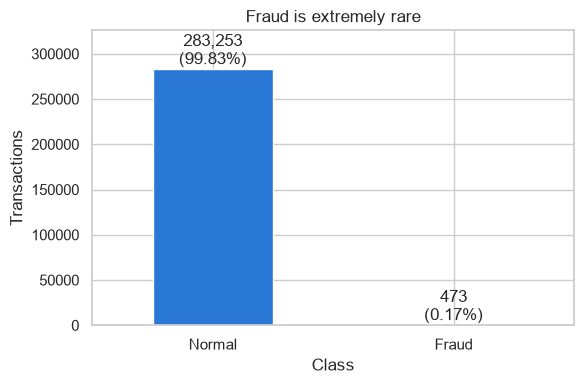

In [5]:

counts = df["Class"].value_counts()                       # how many of each class
pct = df["Class"].value_counts(normalize=True) * 100      # same, as a percentage
print(pd.DataFrame({"transactions": counts, "%": pct.round(3)}).rename(index={0: "Normal", 1: "Fraud"}))

ax = counts.rename(index={0: "Normal", 1: "Fraud"}).plot.bar(color=["#2a78d6", "#e34948"], figsize=(6, 4), rot=0)
ax.set_title("Fraud is extremely rare")
ax.set_ylabel("Transactions")
for i, (c, p) in enumerate(zip(counts, pct)):             # write count and % on each bar
    ax.text(i, c, f"{c:,}\n({p:.2f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(FIGS / "fraud_01_class_imbalance.png", dpi=150)
plt.show()



### 5. Why Accuracy is misleading
A "model" that **always says Normal** catches zero fraud, yet scores almost 100% accuracy.
This is why the project bans accuracy.


In [6]:

X = df.drop(columns="Class")       # inputs (features)
y = df["Class"]                    # answer we want to predict

lazy = DummyClassifier(strategy="most_frequent").fit(X, y)    # always predicts the most common class (0)
pred = lazy.predict(X)
print(f"Accuracy: {accuracy_score(y, pred):.2%}")             # looks amazing
print(f"Recall (fraud caught): {recall_score(y, pred):.0%}")   # catches nothing


Accuracy: 99.83%
Recall (fraud caught): 0%



### 6. Do fraud transactions look different?


In [7]:

# Typical amount for each class
df.groupby("Class")["Amount"].describe().rename(index={0: "Normal", 1: "Fraud"}).round(2)


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normal,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraud,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


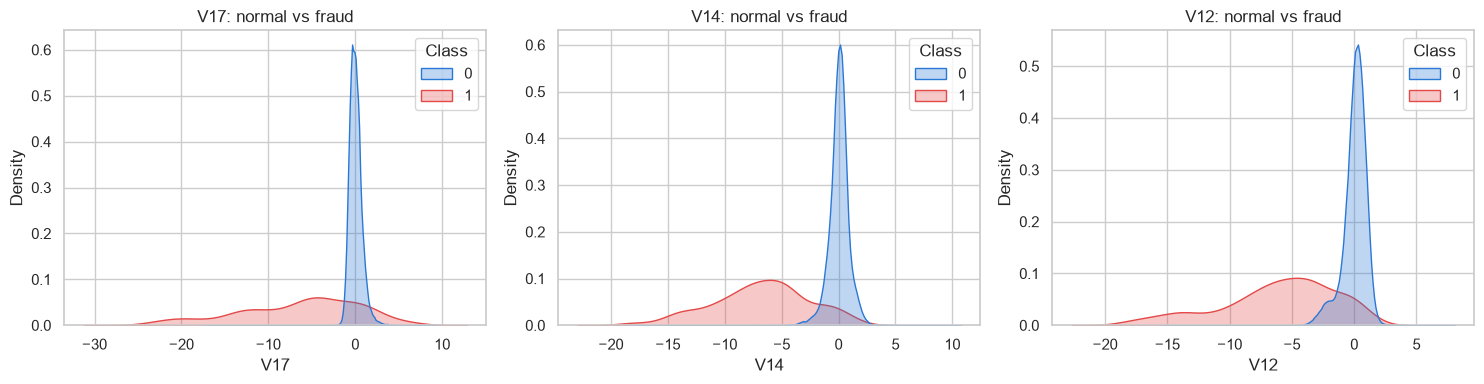

V17    7.68
V14    7.19
V12    6.15
V10    5.07
V16    4.59
dtype: float64

In [8]:

# Which hidden features differ most between fraud and normal? (difference in averages, in std units)
means = df.groupby("Class").mean()
gap = ((means.loc[1] - means.loc[0]) / df.std()).drop("Class").abs().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, gap.index[:3]):                      # the 3 most different features
    sns.kdeplot(data=df, x=col, hue="Class", common_norm=False, ax=ax,
                palette={0: "#2a78d6", 1: "#e34948"}, fill=True, alpha=0.3)
    ax.set_title(f"{col}: normal vs fraud")
plt.tight_layout()
plt.savefig(FIGS / "fraud_02_top_features.png", dpi=150)
plt.show()
gap.head(5).round(2)



### 7. Split into training and test sets
- **Stratified** split: train and test keep the same 0.17% fraud share.
- The test set is locked away until the end, like an exam the model has never seen.


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)       # 80% train, 20% test

print(f"Train: {len(X_train):,} rows, {y_train.sum()} fraud")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} fraud")


Train: 226,980 rows, 378 fraud
Test:  56,746 rows, 95 fraud



### 8. Pipelines: Scale → SMOTE → Model
**SMOTE** makes new, synthetic fraud rows by drawing points between real fraud rows and their nearest fraud neighbours.

It must run **only on the training data**. If synthetic rows leaked into the test set, the scores would be fake.
An `imblearn` Pipeline guarantees this: SMOTE is applied during `fit` (training) and skipped during `predict` (testing).

`sampling_strategy=0.1` means: create fraud rows until fraud = 10% of normal rows (instead of 0.17%).


In [10]:

def evaluate(name, model):
    """Train a model, then score it on the test set with fraud-focused metrics."""
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]          # model's fraud probability for each test row
    pred = (proba >= 0.5).astype(int)                 # call it fraud if probability >= 50%
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "model": name,
        "Precision": precision_score(y_test, pred),       # of flagged transactions, share truly fraud
        "Recall": recall_score(y_test, pred),             # of all fraud, share we caught
        "F1": f1_score(y_test, pred),                     # balance of precision and recall
        "ROC-AUC": roc_auc_score(y_test, proba),          # ranking quality over all thresholds
        "PR-AUC": average_precision_score(y_test, proba), # like ROC-AUC, but stricter for rare classes
        "Fraud caught": f"{tp}/{tp + fn}",
        "False alarms": fp,
    }, proba


results, probas = [], {}                          # store every model's scores and probabilities


#### 8a. Baseline: Logistic Regression without SMOTE

In [11]:

lr_plain = Pipeline([
    ("scale", StandardScaler()),                          # Time and Amount are on big scales; V1-V28 are small
    ("model", LogisticRegression(max_iter=1000)),
])
r, probas["LR (no SMOTE)"] = evaluate("LR (no SMOTE)", lr_plain)
results.append(r); r


{'model': 'LR (no SMOTE)',
 'Precision': 0.8461538461538461,
 'Recall': 0.5789473684210527,
 'F1': 0.6875,
 'ROC-AUC': 0.9560466717268892,
 'PR-AUC': 0.6919665484964556,
 'Fraud caught': '55/95',
 'False alarms': np.int64(10)}

#### 8b. Logistic Regression + SMOTE

In [12]:

lr_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(sampling_strategy=0.1, random_state=SEED)),   # oversample fraud in training data only
    ("model", LogisticRegression(max_iter=1000)),
])
r, probas["LR + SMOTE"] = evaluate("LR + SMOTE", lr_smote)
results.append(r); r


{'model': 'LR + SMOTE',
 'Precision': 0.4,
 'Recall': 0.8,
 'F1': 0.5333333333333333,
 'ROC-AUC': 0.9664286132357955,
 'PR-AUC': 0.6918115634082298,
 'Fraud caught': '76/95',
 'False alarms': np.int64(114)}

#### 8c. Random Forest + SMOTE

In [13]:

rf_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(sampling_strategy=0.1, random_state=SEED)),
    ("model", RandomForestClassifier(
        n_estimators=200,         # 200 decision trees vote together
        min_samples_leaf=2,       # each final leaf needs 2+ rows (reduces overfitting)
        n_jobs=-1,                # use every CPU core
        random_state=SEED)),
])
r, probas["RF + SMOTE"] = evaluate("RF + SMOTE", rf_smote)
results.append(r); r


{'model': 'RF + SMOTE',
 'Precision': 0.9230769230769231,
 'Recall': 0.7578947368421053,
 'F1': 0.8323699421965318,
 'ROC-AUC': 0.9681279375381491,
 'PR-AUC': 0.8123821635412163,
 'Fraud caught': '72/95',
 'False alarms': np.int64(6)}


### 9. Hyperparameter tuning (Logistic Regression)
`GridSearchCV` tries every combination below with **3-fold cross-validation on the training data only**:
- `C`: regularization strength (small C = simpler model)
- SMOTE `sampling_strategy`: how much synthetic fraud to create

Scored with **PR-AUC (average precision)**, the most honest single metric for rare classes.


Best settings: {'model__C': 10, 'smote__sampling_strategy': 0.05}
Best cross-validated PR-AUC: 0.757


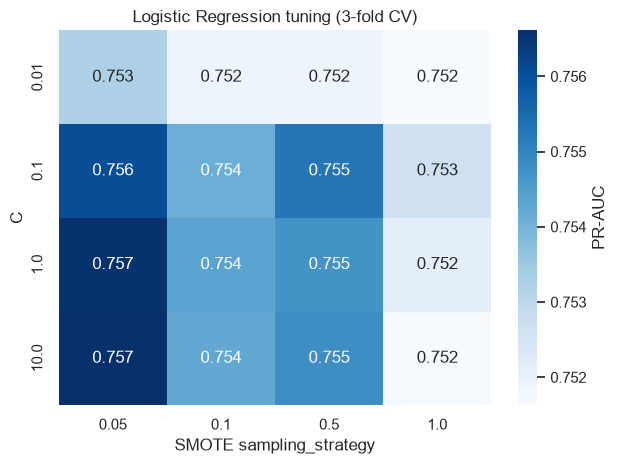

In [14]:

grid = GridSearchCV(
    lr_smote,
    param_grid={
        "model__C": [0.01, 0.1, 1, 10],
        "smote__sampling_strategy": [0.05, 0.1, 0.5, 1.0],
    },
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    n_jobs=2,                     # 2 fits at a time (more can run out of memory)
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print(f"Best cross-validated PR-AUC: {grid.best_score_:.3f}")

# Heat map of all 16 combinations
scores = pd.DataFrame(grid.cv_results_["params"]).assign(score=grid.cv_results_["mean_test_score"])
table = scores.pivot(index="model__C", columns="smote__sampling_strategy", values="score")
ax = sns.heatmap(table, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "PR-AUC"})
ax.set_title("Logistic Regression tuning (3-fold CV)")
ax.set_xlabel("SMOTE sampling_strategy")
ax.set_ylabel("C")
plt.tight_layout()
plt.savefig(FIGS / "fraud_03_lr_tuning.png", dpi=150)
plt.show()


In [15]:

r, probas["LR + SMOTE (tuned)"] = evaluate("LR + SMOTE (tuned)", grid.best_estimator_)
results.append(r)


### 10. Compare all models

In [16]:

comparison = pd.DataFrame(results).set_index("model")
comparison.round(3)


,Precision,Recall,F1,ROC-AUC,PR-AUC,Fraud caught,False alarms
model,,,,,,,
LR (no SMOTE),0.846,0.579,0.688,0.956,0.692,55/95,10
LR + SMOTE,0.400,0.800,0.533,0.966,0.692,76/95,114
RF + SMOTE,0.923,0.758,0.832,0.968,0.812,72/95,6
LR + SMOTE (tuned),0.694,0.789,0.739,0.966,0.695,75/95,33


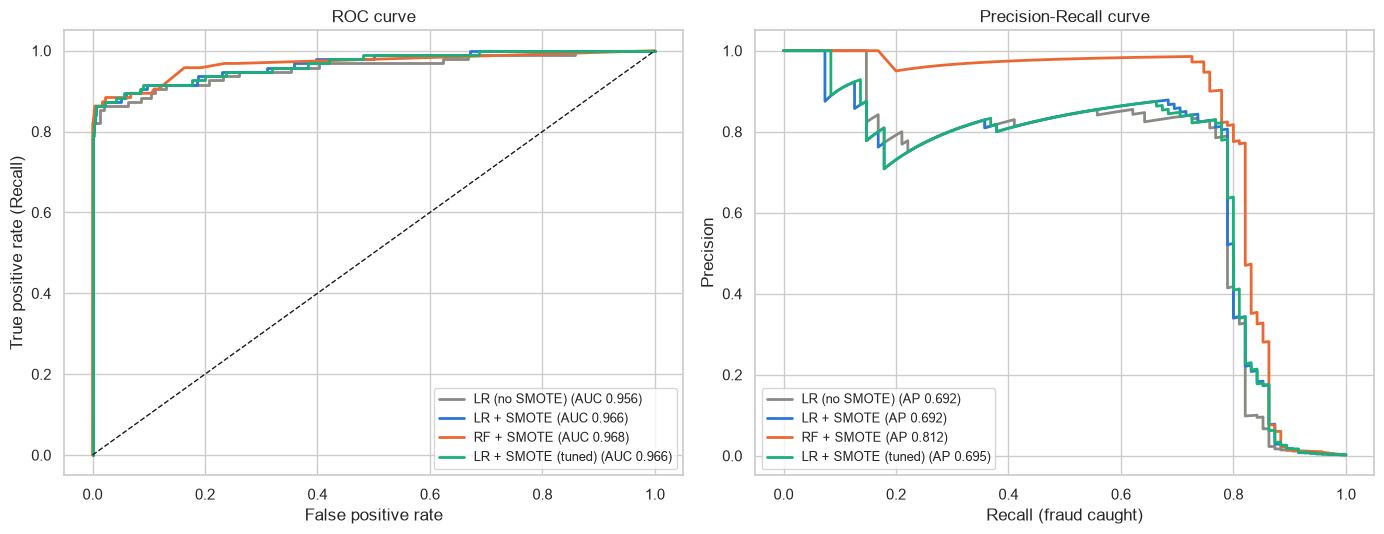

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ["#8a8984", "#2a78d6", "#eb6834", "#1baf7a"]

for (name, proba), c in zip(probas.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, color=c, lw=2, label=f"{name} (AP {average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)                 # random guessing line
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate (Recall)")
axes[1].set(title="Precision-Recall curve", xlabel="Recall (fraud caught)", ylabel="Precision")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
plt.tight_layout()
plt.savefig(FIGS / "fraud_04_roc_pr_curves.png", dpi=150)
plt.show()


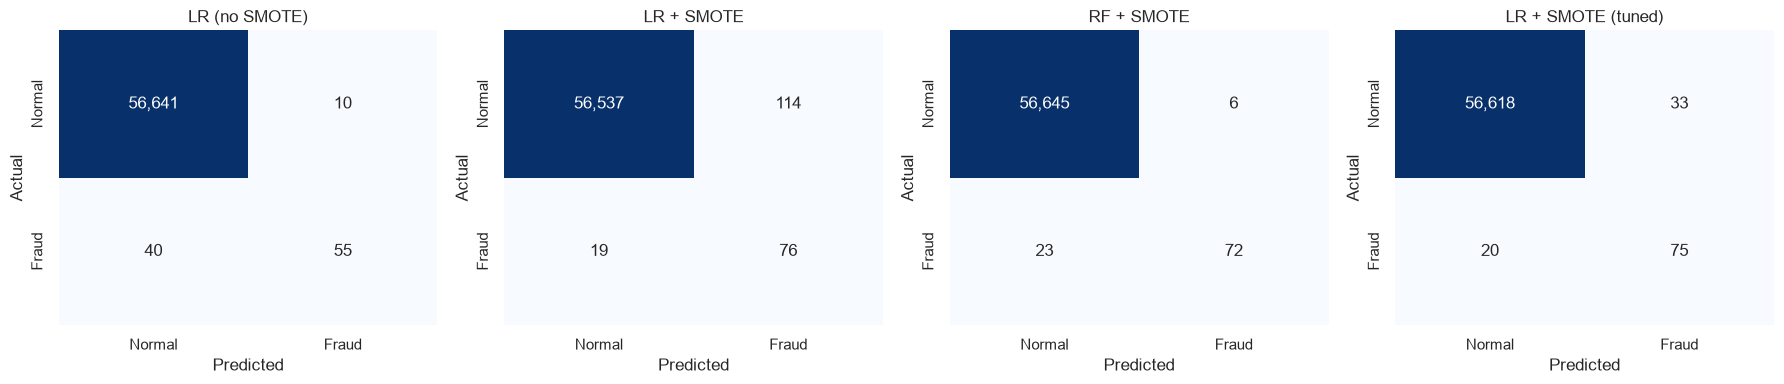

In [18]:

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, proba) in zip(axes, probas.items()):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.savefig(FIGS / "fraud_05_confusion_matrices.png", dpi=150)
plt.show()



### 11. Choosing the decision threshold
The models output a fraud **probability**. By default we flag fraud at 50%, but a bank can move that line:
- **Lower threshold** → catch more fraud (higher recall) but more false alarms (lower precision)
- **Higher threshold** → fewer false alarms but more fraud slips through


In [19]:

best_name = comparison["PR-AUC"].idxmax()             # model with the best PR-AUC
proba = probas[best_name]
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"threshold": t, "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "Fraud caught": tp, "Fraud missed": fn, "False alarms": fp})
print("Model:", best_name)
pd.DataFrame(rows).set_index("threshold").round(3)


Model: RF + SMOTE


,Precision,Recall,Fraud caught,Fraud missed,False alarms
threshold,,,,,
0.1,0.353,0.832,79,16,145
0.2,0.690,0.821,78,17,35
0.3,0.792,0.800,76,19,20
0.4,0.881,0.779,74,21,10
0.5,0.923,0.758,72,23,6
0.6,0.973,0.747,71,24,2
0.7,0.972,0.726,69,26,2
0.8,0.986,0.716,68,27,1
0.9,0.983,0.611,58,37,1


### 12. What does the Random Forest rely on?

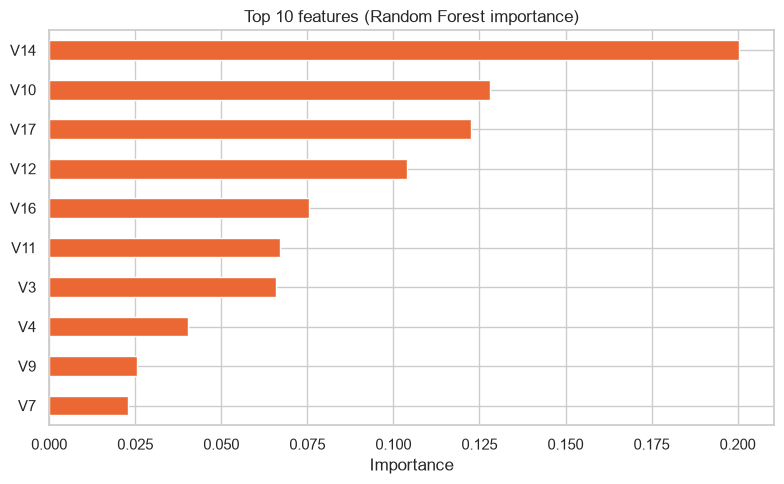

In [20]:

rf = rf_smote.named_steps["model"]                    # the trained forest inside the pipeline
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

ax = importance.head(10).sort_values().plot.barh(color="#eb6834", figsize=(8, 5))
ax.set_title("Top 10 features (Random Forest importance)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(FIGS / "fraud_06_feature_importance.png", dpi=150)
plt.show()


---
## Final Summary — Project 2

**Data:** 283,726 transactions after removing 1,081 exact duplicates; only **473 fraud (0.17%)**.
A model that always says "normal" is **99.83% accurate but catches 0% of fraud**, which is why accuracy was not used.

**Results on the untouched test set (95 fraud cases, threshold 0.5)**

| Model | Precision | Recall | ROC-AUC | PR-AUC | Fraud caught | False alarms |
|---|---|---|---|---|---|---|
| LR (no SMOTE) | 0.85 | 0.58 | 0.956 | 0.69 | 55/95 | 10 |
| LR + SMOTE | 0.40 | 0.80 | 0.966 | 0.69 | 76/95 | 114 |
| LR + SMOTE (tuned) | 0.69 | 0.79 | 0.966 | 0.70 | 75/95 | 33 |
| **RF + SMOTE** | **0.92** | **0.76** | **0.968** | **0.81** | **72/95** | **6** |

**Key findings**
- **SMOTE raised Logistic Regression's recall from 58% to 80%** (21 more frauds caught), at the cost of many more false alarms.
- **Tuning** (C = 10, sampling_strategy = 0.05) cut LR's false alarms from 114 to 33 while keeping recall at 79%. Less synthetic data worked better than more.
- **Random Forest + SMOTE was the best model**: highest PR-AUC (0.81) and only 6 false alarms out of 56,651 normal transactions.
- **ROC-AUC looks great for every model (0.96+)** because normal transactions are so many; **PR-AUC** shows the real gap between models.
- **The threshold is a business decision.** For the Random Forest, a 0.3 threshold catches 76/95 fraud with 20 false alarms; 0.6 catches 71/95 with only 2.
- V14, V17, V12 and V10 separate fraud from normal transactions most strongly.
